In [1]:
from medmnist import PathMNIST
from torchvision import transforms

In [2]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train = PathMNIST(split="train", transform=transform, download=False)
val   = PathMNIST(split="val",   transform=transform, download=False)
test  = PathMNIST(split="test",  transform=transform, download=False)

In [ ]:
# breast cancer dataset


In [3]:
# Dataset info
print(f"Training samples: {len(train)}")
print(f"Validation samples: {len(val)}")
print(f"Test samples: {len(test)}")
print(f"Image shape: {train[0][0].shape}")
print(f"Number of classes: {len(train.info['label'])}")
print(f"Class labels: {train.info['label']}")

Training samples: 89996
Validation samples: 10004
Test samples: 7180
Image shape: torch.Size([3, 224, 224])
Number of classes: 9
Class labels: {'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models
from tqdm import tqdm

# Configuration
BATCH_SIZE = 128
NUM_EPOCHS = 20
LEARNING_RATE = 0.001

# Use MPS (Metal Performance Shaders) for faster training on macOS
if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(train)

else:
    print("train is:")

    device = torch.device('cpu')

    print(f'Using device: {device}')

In [5]:
# Create data loaders
train_loader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f'Training batches: {len(train_loader)}')

# Create subset data loaders for faster training (25% of data)
from torch.utils.data import Subset
import numpy as np

x_train_indices = np.arange(0, int(len(train)/4))
x_val_indices = np.arange(0, int(len(val)/4))

x_train = Subset(train, x_train_indices)
x_val = Subset(val, x_val_indices)

x_train_loader = DataLoader(x_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
x_val_loader = DataLoader(x_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f'Reduced training batches: {len(x_train_loader)} (25% of data)')

Training batches: 704
Reduced training batches: 176 (25% of data)


In [6]:
images, labels = next(iter(train_loader))
image = images[0]
print(image.shape)

torch.Size([3, 224, 224])


In [7]:
import torch.nn as nn
import torchvision.models as models

class AlexNetMedical(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.model = models.alexnet(pretrained=True)

        self.model.classifier[6] = nn.Linear(
            self.model.classifier[6].in_features,
            num_classes
        )

    def forward(self, x):
        return self.model(x)


In [8]:
# Initialize AlexNetMedical model
num_classes = len(train.info['label'])

medical_model = AlexNetMedical(num_classes=num_classes)
medical_model = medical_model.to(device)

print(f"AlexNetMedical loaded with {num_classes} output classes")


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /Users/ameyakhanzode/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 233M/233M [00:06<00:00, 36.6MB/s] 


AlexNetMedical loaded with 9 output classes


In [ ]:
# Loss function and optimizer for medical model
medical_criterion = nn.CrossEntropyLoss()
medical_optimizer = optim.Adam(medical_model.parameters(), lr=LEARNING_RATE)
medical_scheduler = optim.lr_scheduler.ReduceLROnPlateau(medical_optimizer, mode='min', patience=2, factor=0.5)

: 

In [ ]:
# Training loop for ResNet18Medical
medical_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_medical_val_acc = 0.0

for epoch in range(NUM_EPOCHS):
    print(f'\nEpoch {epoch+1}/{NUM_EPOCHS}')
    print('-' * 50)
    
    # Training phase
    medical_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    
    for images, labels in tqdm(train_loader, desc='Training'):
        images = images.to(device)
        labels = labels.squeeze().long().to(device)
        
        medical_optimizer.zero_grad()
        outputs = medical_model(images)
        loss = medical_criterion(outputs, labels)
        loss.backward()
        medical_optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = 100 * train_correct / train_total
    
    # Validation phase
    medical_model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc='Validation'):
            images = images.to(device)
            labels = labels.squeeze().long().to(device)
            
            outputs = medical_model(images)
            loss = medical_criterion(outputs, labels)
            
            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = 100 * val_correct / val_total
    
    # Update scheduler
    medical_scheduler.step(epoch_val_loss)
    
    # Save history
    medical_history['train_loss'].append(epoch_train_loss)
    medical_history['train_acc'].append(epoch_train_acc)
    medical_history['val_loss'].append(epoch_val_loss)
    medical_history['val_acc'].append(epoch_val_acc)
    
    print(f'Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%')
    print(f'Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}%')
    
    # Save best model
    if epoch_val_acc > best_medical_val_acc:
        best_medical_val_acc = epoch_val_acc
        torch.save(medical_model.state_dict(), 'resnet18medical_pathmnist.pth')
        print(f'✓ Model saved with val acc: {best_medical_val_acc:.2f}%')

print(f'\nTraining complete! Best validation accuracy: {best_medical_val_acc:.2f}%')


Epoch 1/20
--------------------------------------------------


Validation: 100%|██████████| 79/79 [00:22<00:00,  3.50it/s]


Train Loss: 2.1884 | Train Acc: 14.18%
Val Loss: 2.1862 | Val Acc: 14.31%
✓ Model saved with val acc: 14.31%

Epoch 2/20
--------------------------------------------------


Validation: 100%|██████████| 79/79 [00:23<00:00,  3.40it/s]


Train Loss: 2.1858 | Train Acc: 14.17%
Val Loss: 2.1851 | Val Acc: 14.31%

Epoch 3/20
--------------------------------------------------


Validation: 100%|██████████| 79/79 [00:23<00:00,  3.36it/s]


Train Loss: 2.1856 | Train Acc: 14.23%
Val Loss: 2.1853 | Val Acc: 13.53%

Epoch 4/20
--------------------------------------------------


Training:  99%|█████████▊| 695/704 [05:26<00:04,  2.13it/s]

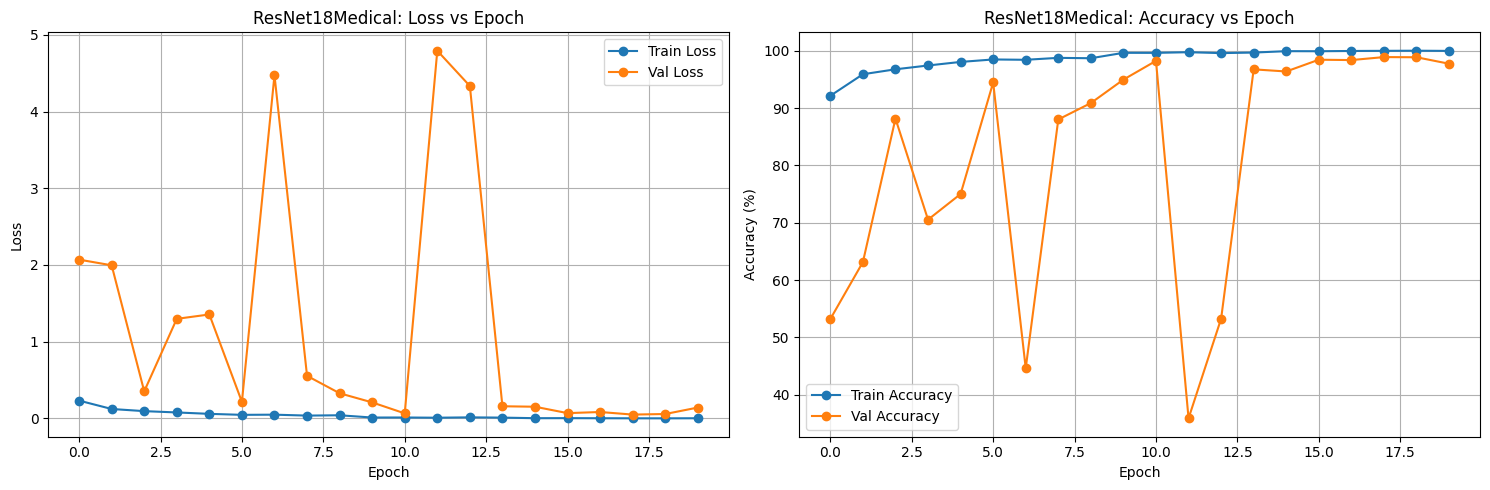

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(medical_history['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ---- Loss plot ----
ax1.plot(epochs, medical_history['train_loss'], label='Train Loss')
ax1.plot(epochs, medical_history['val_loss'], label='Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('AlexNetMedical: Loss vs Epoch')
ax1.legend()
ax1.grid(True)

# ---- Accuracy plot ----
ax2.plot(epochs, medical_history['train_acc'], label='Train Accuracy')
ax2.plot(epochs, medical_history['val_acc'], label='Validation Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_ylim(0, 100)
ax2.set_title('AlexNetMedical: Accuracy vs Epoch')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.savefig('alexnetmedical_training_curves.png', dpi=300)
plt.show()


In [ ]:
# Evaluate ResNet18Medical on test set
medical_model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='Testing AlexNetMedical'):
        images = images.to(device)
        labels = labels.squeeze().long().to(device)
        
        outputs = medical_model(images)
        _, predicted = torch.max(outputs, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_acc = 100 * test_correct / test_total
print(f'AlexNetMedical Test Accuracy: {test_acc:.2f}%')

Testing ResNet18Medical: 100%|██████████| 57/57 [00:17<00:00,  3.32it/s]

ResNet18Medical Test Accuracy: 91.80%


In [ ]:
torch.save(medical_model.state_dict(), "../models/alexnet_full.pth")